# The automated workflow

Most of the time you don't want to call each step by hand. `run_dynamic_workflow` takes a raw
well, works out which curves it has, and runs the whole chain (temperature, clay, porosity,
lithology, water resistivity, saturation, permeability, net pay), skipping anything it can't
support. It returns the well with all the computed curves added, plus a record of what it did.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
WELL = REPO / "src" / "petrophys" / "datasets" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
well = read_las(WELL)
result = run_dynamic_workflow(well, lithology="clastic")
print("ran:", [s.step for s in result.steps_executed])
print("skipped:", result.steps_skipped)

ran: ['temperature', 'bad_hole', 'vclay', 'rcl', 'porosity', 'lithology', 'core_correction', 'rw', 'invasion', 'saturation', 'permeability', 'rock_quality', 'bvw', 'mhi', 'net_pay']
skipped: ['rmf', 'hc_correction', 'porosity_refinement']


Two things to notice. First, you only told it the rock is clastic. It figured out the rest
from the curves. Second, it tells you what it skipped and why, so a missing log never fails
silently. The full reasoning is available (see the *glass-box workflow* deep dive); here we just
look at the result.

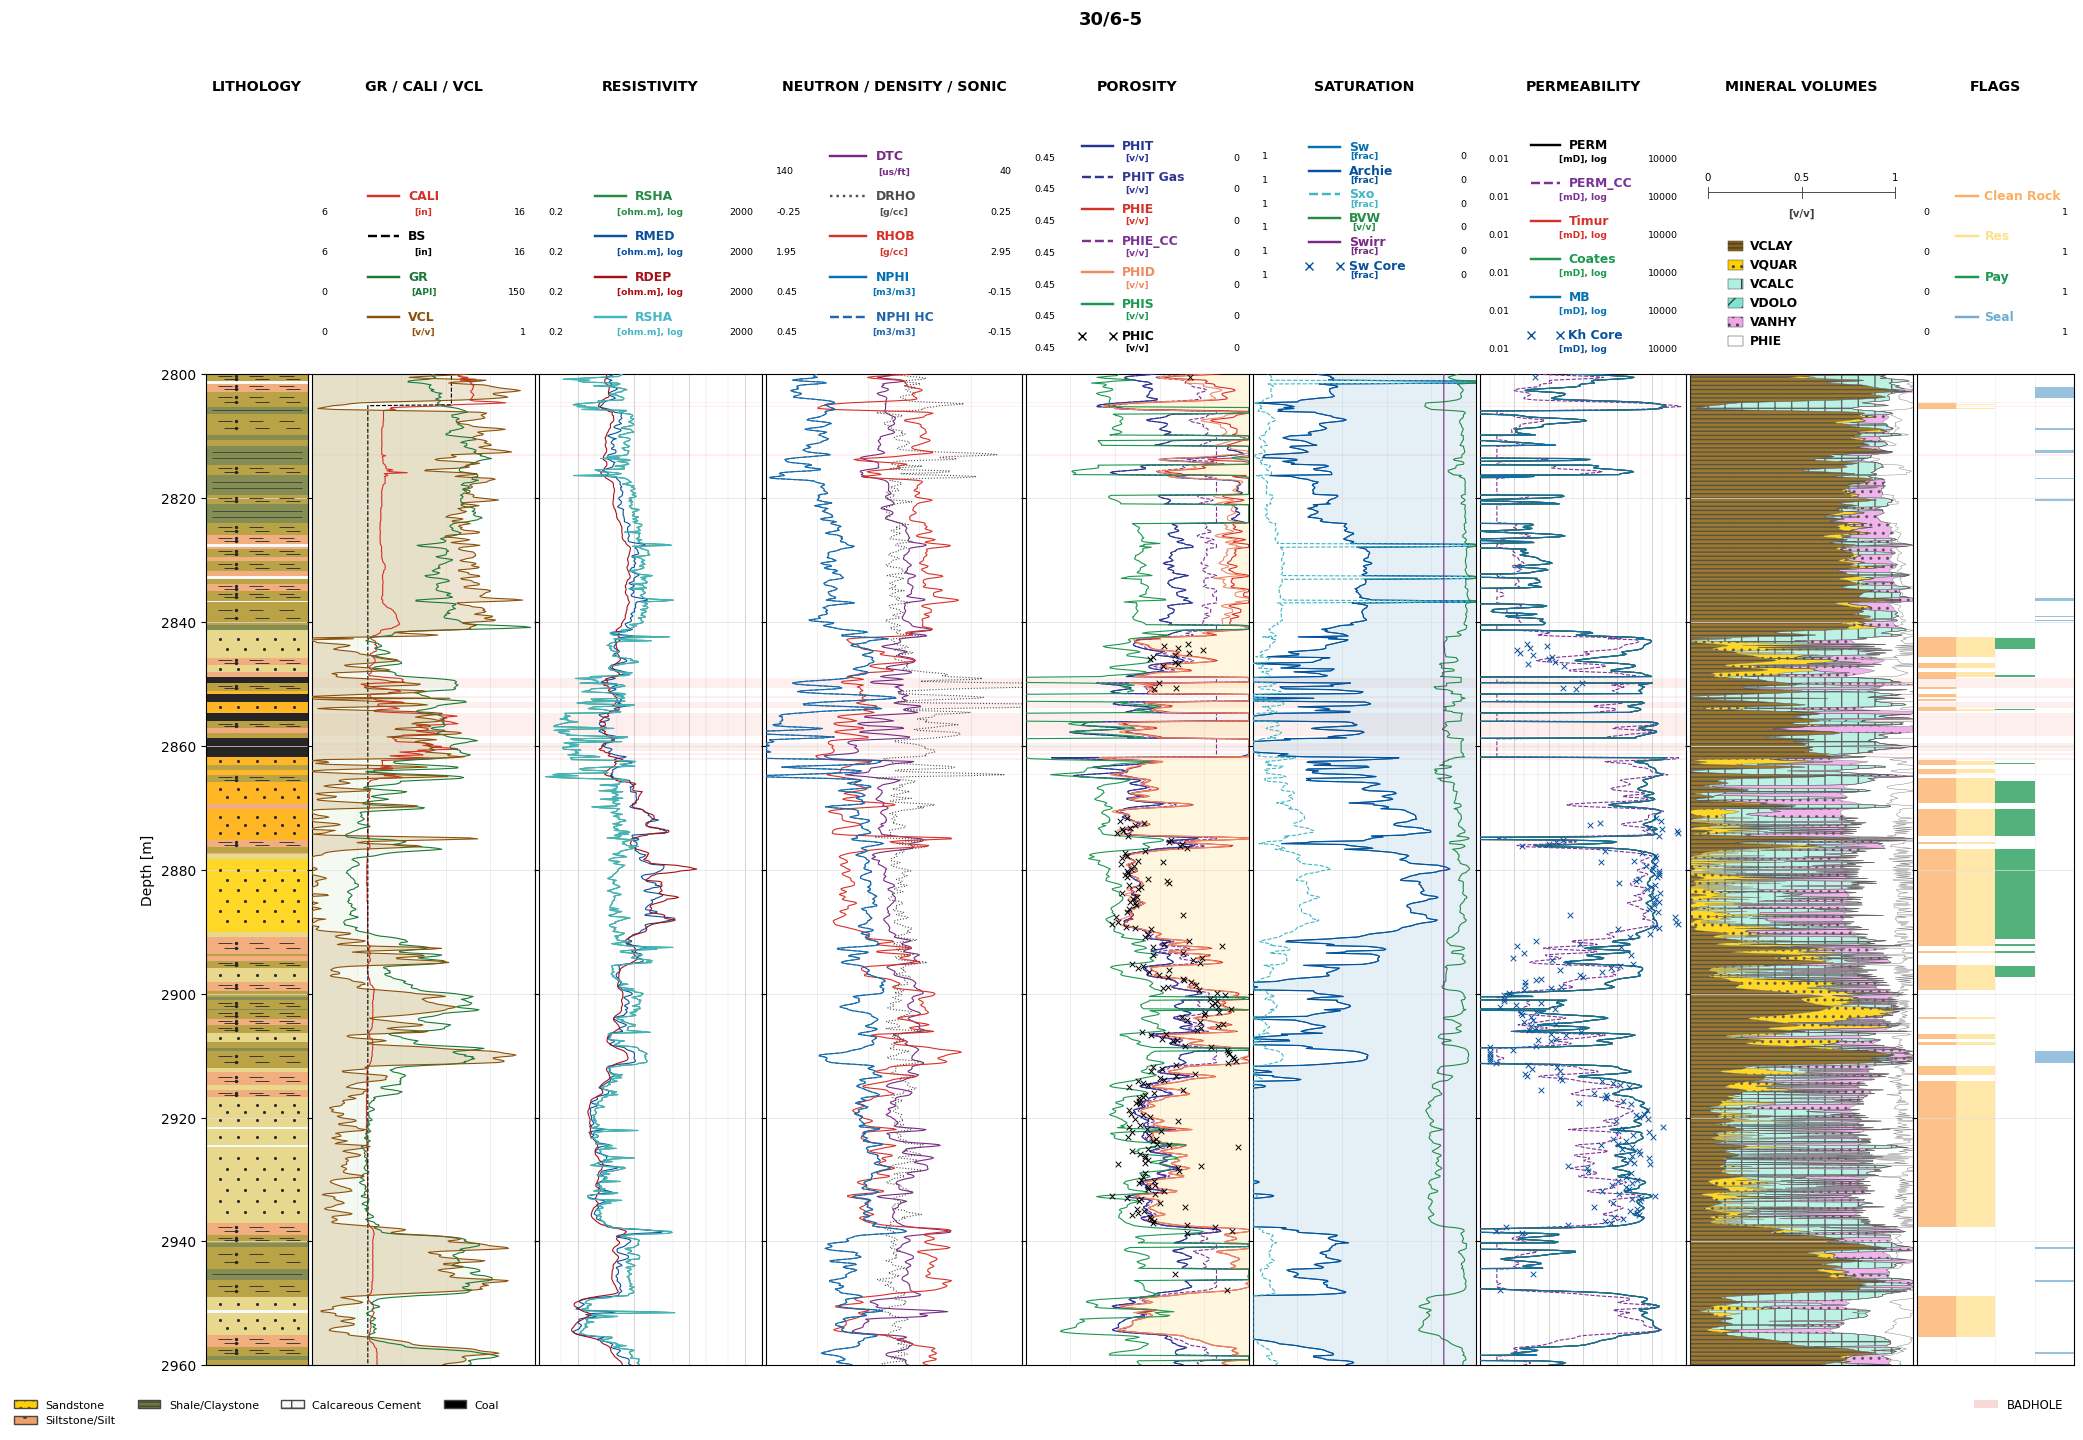

In [2]:
from petrophys.visualization import create_log_viewer
create_log_viewer(well, template_defaults="full", depth_range=(2800, 2960));

Left to right: a lithology strip, gamma ray with clay volume, resistivity, the
density-neutron-sonic logs, porosity (total and effective, with the core plugs overlaid as
points), water saturation, permeability, the mineral volumes, and the net-pay flags. That's a
complete first-pass interpretation from one function call. The rest of the notebooks open up the
individual steps.